# C2 추가 실험 (비교 범위 확장, 조합, epoch 상한, ALS)

`C2_mf_tuning.ipynb`의 한계를 보완하는 실험입니다. 같은 기록 파일(`C2_tuning_runs.csv`)에 이어서 저장하고, 끝난 실험은 다시 돌리지 않습니다.

| 보완할 점 | 여기서 하는 실험 |
| --- | --- |
| 추천용 학습률을 0.02만 씀 | 학습률 0.01, 0.04 추가 |
| neg_ratio 4, 차원 64가 비교 범위의 가장 큰 값에서 최고 | neg_ratio 8, 차원 128 추가 |
| 한 번에 한 값만 바꿔 조합을 못 봄 | neg_ratio(4, 8) x 차원(64, 128) 네 조합 모두 비교 |
| 별점 예측용에서 epoch 상한(40)에 걸린 후보가 있음 | 상한을 150으로 올려 차원 8·16·32·64·128을 다시 비교(학습률 0.01) |
| 제안서의 "ALS 등 다른 최적화 방법" | ALS로 학습한 MF와 검증 RMSE 비교 |

모든 후보는 `train`만 학습하고 `val`로만 비교합니다. `test`와 `cold_final`은 쓰지 않습니다.

In [1]:
import time
from dataclasses import asdict, replace

import matplotlib.pyplot as plt
import pandas as pd

from bookrec.data import load_split
from bookrec.evaluation import evaluate_rmse, evaluate_warm
from bookrec.models.collaborative_filtering import MFConfig
from bookrec.models.collaborative_filtering.als import ALSMatrixFactorization
from bookrec.models.collaborative_filtering.tuning import RESULT_DIR, SELECTED_PATH, TUNING_USERS, run_experiment, save_selected
from bookrec.models.popularity import PopularityRecommender
from bookrec.plot_style import MODEL_COLORS, save, setup

setup()
split = load_split()
popularity_ndcg = evaluate_warm(PopularityRecommender().fit(split.train), split, on="val", n_users=TUNING_USERS)["ndcg@10"]

RUNS_PATH, EPOCHS_PATH = RESULT_DIR / "C2_tuning_runs.csv", RESULT_DIR / "C2_epoch_history.csv"
defaults = asdict(MFConfig())
runs = pd.read_csv(RUNS_PATH).to_dict("records")
epoch_histories = [pd.read_csv(EPOCHS_PATH)]
# NOTE: CSV에서 읽으면 정수가 실수로 바뀌는 경우가 있어, 기본 설정의 자료형(int, float)으로 다시 맞춘다.
finished = {(record["purpose"], MFConfig(**{name: type(default)(record[name]) for name, default in defaults.items()})): record for record in runs}
print(f"이전에 끝난 실험 {len(runs)}개를 읽었습니다.")


def run(purpose: str, config: MFConfig) -> dict:
    """설정 하나를 학습·채점하고 기록한다. 이미 끝난 설정이면 저장된 기록을 돌려준다."""
    if (purpose, config) not in finished:
        record, model = run_experiment(config, split, purpose)
        record["run_id"] = f"{purpose}-{len(runs) + 1:02d}"
        finished[(purpose, config)] = record
        runs.append(record)
        epoch_histories.append(model.history.assign(run_id=record["run_id"]))
        pd.DataFrame(runs).to_csv(RUNS_PATH, index=False)
        pd.concat(epoch_histories).to_csv(EPOCHS_PATH, index=False)
    record = finished[(purpose, config)]
    print(f"[{record['run_id']}] 차원 {config.n_factors}, 학습률 {config.lr}, 정규화 {config.reg}, neg_ratio {config.neg_ratio}: "
          f"val RMSE {record['val_rmse']:.4f}, val NDCG@10 {record['val_ndcg@10']:.4f}, epoch {record['best_epoch']}/{record['epochs_run']}, {record['train_seconds']:.0f}초")
    return record


COLUMNS = ["run_id", "n_factors", "lr", "reg", "neg_ratio", "n_epochs", "best_epoch", "epochs_run", "val_rmse", "val_ndcg@10", "train_seconds"]

이전에 끝난 실험 20개를 읽었습니다.


## 1. ALS와 gradient descent 비교 (별점 예측)

ALS는 책 쪽을 고정하고 독자 쪽을 Ridge regression의 닫힌 해로 구하고, 다음에는 독자 쪽을 고정하고 책 쪽을 구하는 것을 번갈아 반복합니다.
학습률이 없고 정규화 세기만 정하면 됩니다. 구현은 `src/bookrec/models/collaborative_filtering/als.py`에 있습니다.
차원은 64로 두고 정규화 세기를 바꿔 가며 검증 RMSE를 잽니다.

In [2]:
ALS_PATH = RESULT_DIR / "C2b_als_runs.csv"
als_runs = pd.read_csv(ALS_PATH).to_dict("records") if ALS_PATH.exists() else []
for record in als_runs:
    record.setdefault("n_epochs", 20)
# NOTE: 먼저 최대 20 epoch로 정규화 세기 네 값을 비교하고, 가장 좋았던 0.1 주변(0.08, 0.15)을 추가로 본다.
#       0.1은 20 epoch에서도 검증 RMSE가 계속 내려가고 있어서 상한을 60으로 올려 한 번 더 학습한다.
for reg, n_epochs in [(0.05, 20), (0.1, 20), (0.2, 20), (0.3, 20), (0.08, 20), (0.15, 20), (0.1, 60)]:
    if not any(record["reg"] == reg and record["n_epochs"] == n_epochs for record in als_runs):
        started = time.time()
        als = ALSMatrixFactorization(n_factors=64, reg=reg, n_epochs=n_epochs, patience=2).fit(split.train, val=split.val)
        best = als.history[als.history["epoch"] == als.best_epoch].iloc[0]
        als_runs.append({"optimizer": "ALS", "n_factors": 64, "reg": reg, "n_epochs": n_epochs, "best_epoch": als.best_epoch, "epochs_run": len(als.history),
                         "train_rmse": best["train_rmse"], "val_rmse": best["val_rmse"], "train_seconds": round(time.time() - started, 1)})
        pd.DataFrame(als_runs).to_csv(ALS_PATH, index=False)
pd.DataFrame(als_runs).round(4)

,optimizer,n_factors,reg,best_epoch,epochs_run,train_rmse,val_rmse,train_seconds,n_epochs
0,ALS,64,0.05,19,20,0.4683,0.8700,121.2,20
1,ALS,64,0.10,20,20,0.6842,0.8392,123.6,20
2,ALS,64,0.20,20,20,0.8417,0.8615,122.9,20
3,ALS,64,0.30,10,12,0.8515,0.8657,72.7,20
4,ALS,64,0.08,19,20,0.6060,0.8425,123.0,20
5,ALS,64,0.15,20,20,0.8090,0.8506,120.9,20
6,ALS,64,0.10,25,27,0.6831,0.8392,160.8,60


## 2. 추천용: 학습률, 더 큰 neg_ratio·차원, 조합

C2에서 고른 설정(차원 64, 학습률 0.02, 정규화 0.05, neg_ratio 4)에서 출발합니다.

In [3]:
ranking_c2 = MFConfig(n_factors=64, lr=0.02, reg=0.05, neg_ratio=4, n_epochs=20, patience=2)
lr_records = [run("ranking", replace(ranking_c2, lr=lr)) for lr in [0.01, 0.02, 0.04]]

[ranking-16] 차원 64, 학습률 0.01, 정규화 0.05, neg_ratio 4: val RMSE 2.2539, val NDCG@10 0.0689, epoch 4/6, 220초
[ranking-13] 차원 64, 학습률 0.02, 정규화 0.05, neg_ratio 4: val RMSE 2.2312, val NDCG@10 0.0672, epoch 4/6, 226초
[ranking-17] 차원 64, 학습률 0.04, 정규화 0.05, neg_ratio 4: val RMSE 2.2502, val NDCG@10 0.0610, epoch 2/4, 144초


In [4]:
grid_records = [run("ranking", replace(ranking_c2, neg_ratio=neg_ratio, n_factors=n_factors)) for neg_ratio in [4, 8] for n_factors in [64, 128]]
grid = pd.DataFrame(grid_records).pivot(index="neg_ratio", columns="n_factors", values="val_ndcg@10")
grid.round(4)

[ranking-13] 차원 64, 학습률 0.02, 정규화 0.05, neg_ratio 4: val RMSE 2.2312, val NDCG@10 0.0672, epoch 4/6, 226초
[ranking-18] 차원 128, 학습률 0.02, 정규화 0.05, neg_ratio 4: val RMSE 2.2361, val NDCG@10 0.0684, epoch 4/6, 436초
[ranking-19] 차원 64, 학습률 0.02, 정규화 0.05, neg_ratio 8: val RMSE 2.5214, val NDCG@10 0.0689, epoch 5/7, 403초
[ranking-20] 차원 128, 학습률 0.02, 정규화 0.05, neg_ratio 8: val RMSE 2.5265, val NDCG@10 0.0706, epoch 4/6, 671초


n_factors,64,128
neg_ratio,,
4,0.0672,0.0684
8,0.0689,0.0706


학습률 0.01이 0.02보다 조금 높았으므로, 위 네 조합 중 가장 좋은 조합에서도 학습률 0.01을 확인합니다.

In [5]:
best_cell = max(grid_records, key=lambda record: record["val_ndcg@10"])
best_cell_slow = run("ranking", replace(ranking_c2, neg_ratio=int(best_cell["neg_ratio"]), n_factors=int(best_cell["n_factors"]), lr=0.01))

[ranking-21] 차원 128, 학습률 0.01, 정규화 0.05, neg_ratio 8: val RMSE 2.5359, val NDCG@10 0.0723, epoch 4/6, 967초


## 3. 별점 예측용: epoch 상한을 올려 다시 비교

C2에서는 최대 40 epoch로 두었는데, 학습률 0.005인 후보들이 40 epoch 근처까지 가서 early stopping으로 멈춘 것인지 상한에 걸린 것인지 구분되지 않았습니다.
상한을 150으로 올립니다. 차원 비교는 C2에서 early stopping으로 제대로 멈췄던 학습률 0.01로 하고(학습률 0.005와의 차이는 0.0004), 차원 128을 추가합니다.

In [6]:
rating_base = MFConfig(n_factors=64, lr=0.01, reg=0.05, neg_ratio=0, n_epochs=150, patience=2)
factor_records = [run("rating", replace(rating_base, n_factors=n_factors)) for n_factors in [8, 16, 32, 64, 128]]

[rating-22] 차원 8, 학습률 0.01, 정규화 0.05, neg_ratio 0: val RMSE 0.8496, val NDCG@10 0.0027, epoch 23/25, 41초


[rating-23] 차원 16, 학습률 0.01, 정규화 0.05, neg_ratio 0: val RMSE 0.8489, val NDCG@10 0.0033, epoch 21/23, 66초


[rating-24] 차원 32, 학습률 0.01, 정규화 0.05, neg_ratio 0: val RMSE 0.8477, val NDCG@10 0.0031, epoch 21/23, 120초


[rating-25] 차원 64, 학습률 0.01, 정규화 0.05, neg_ratio 0: val RMSE 0.8465, val NDCG@10 0.0031, epoch 20/22, 198초


[rating-26] 차원 128, 학습률 0.01, 정규화 0.05, neg_ratio 0: val RMSE 0.8453, val NDCG@10 0.0032, epoch 22/24, 418초


## 4. 정리와 최종 설정

지금까지의 모든 후보(C2 + 추가 실험)에서 용도별로 가장 좋은 설정을 다시 고릅니다.
별점 예측용은 early stopping으로 멈춘 후보(상한에 걸리지 않은 후보)만 대상으로 합니다.

In [7]:
all_runs = pd.DataFrame(runs)
ranking_runs = all_runs[all_runs["purpose"] == "ranking"]
rating_runs = all_runs[(all_runs["purpose"] == "rating") & (all_runs["epochs_run"] < all_runs["n_epochs"])]
best_ranking = ranking_runs.loc[ranking_runs["val_ndcg@10"].idxmax()]
best_rating = rating_runs.loc[rating_runs["val_rmse"].idxmin()]
previous = __import__("json").loads(SELECTED_PATH.read_text())
selected = {}
for purpose, record in [("rating", best_rating), ("ranking", best_ranking)]:
    config = MFConfig(**{name: type(default)(record[name]) for name, default in defaults.items()})
    selected[purpose] = {
        "run_id": record["run_id"],
        "optimizer": "gradient_descent",
        "config": asdict(replace(config, n_epochs=int(record["best_epoch"]))),
        "criterion": "lowest val RMSE among early-stopped runs" if purpose == "rating" else f"highest val NDCG@10 on {TUNING_USERS} val users (seed 42)",
        "val_rmse": float(record["val_rmse"]),
        "val_ndcg@10": float(record["val_ndcg@10"]),
        "train_source": "split.train",
        "final_evaluation_performed": False,
    }
# NOTE: 별점 예측용은 ALS가 gradient descent보다 검증 RMSE가 낮으면 ALS를 최종 모델로 한다(제안서 3.2: 결과가 좋은 최적화 방법을 고름).
best_als = min(als_runs, key=lambda record: record["val_rmse"])
if best_als["val_rmse"] < selected["rating"]["val_rmse"]:
    selected["rating"] = {
        "run_id": f"als-reg{best_als['reg']}",
        "optimizer": "als",
        "config": {"n_factors": int(best_als["n_factors"]), "reg": float(best_als["reg"]), "n_epochs": int(best_als["best_epoch"]), "patience": 2, "seed": 42},
        "criterion": "lowest val RMSE among gradient descent and ALS runs",
        "val_rmse": float(best_als["val_rmse"]),
        "train_source": "split.train",
        "final_evaluation_performed": False,
    }
for purpose in selected:
    print(f"{purpose}: 이전 {previous[purpose]['run_id']} → 지금 {selected[purpose]['run_id']}")
save_selected(selected)
pd.concat([best_rating[COLUMNS], best_ranking[COLUMNS]], axis=1).T

rating: 이전 rating-06 → 지금 als-reg0.1
ranking: 이전 ranking-13 → 지금 ranking-21


,run_id,n_factors,lr,reg,neg_ratio,n_epochs,best_epoch,epochs_run,val_rmse,val_ndcg@10,train_seconds
25,rating-26,128,0.01,0.05,0,150,22,24,0.845295,0.003182,417.7
20,ranking-21,128,0.01,0.05,8,20,4,6,2.535851,0.072333,966.7


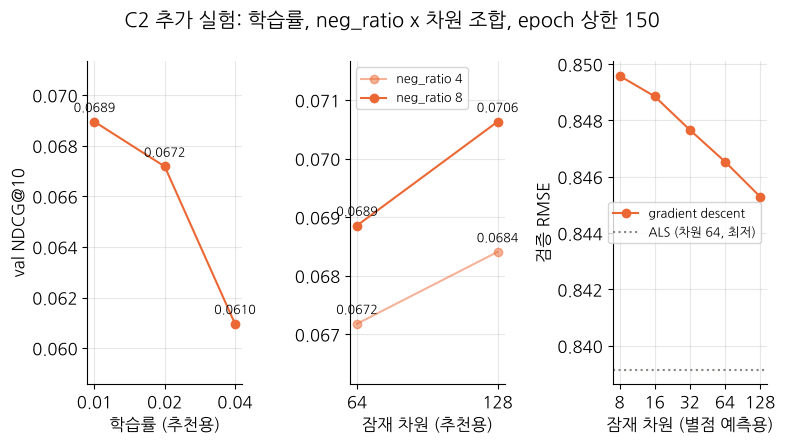

,run_id,n_factors,lr,reg,neg_ratio,n_epochs,best_epoch,epochs_run,val_rmse,val_ndcg@10,train_seconds
0,rating-01,32,0.005,0.05,0,40,39,40,0.8473,0.0029,170.3
1,rating-02,32,0.010,0.05,0,40,21,23,0.8477,0.0031,99.2
2,rating-03,32,0.020,0.05,0,40,11,13,0.8489,0.0027,53.1
3,rating-04,8,0.005,0.05,0,40,40,40,0.8496,0.0033,57.1
4,rating-05,16,0.005,0.05,0,40,40,40,0.8487,0.0037,93.9
5,rating-06,64,0.005,0.05,0,40,39,40,0.8463,0.0033,289.5
6,rating-07,64,0.005,0.02,0,40,17,19,0.8574,0.0064,136.7
7,rating-08,64,0.005,0.10,0,40,10,12,0.8626,0.0011,89.5
8,ranking-09,32,0.020,0.05,1,20,2,4,1.7405,0.0541,51.3
9,ranking-10,32,0.020,0.05,2,20,4,6,1.9427,0.0601,97.9


In [8]:
fig, axes = plt.subplots(1, 3)
lr_table = pd.DataFrame(lr_records)
axes[0].plot(lr_table["lr"].astype(str), lr_table["val_ndcg@10"], color=MODEL_COLORS["mf"], marker="o")
axes[0].set_xlabel("학습률 (추천용)")
axes[0].set_ylabel("val NDCG@10")
axes[0].margins(y=0.3)
for x, y in zip(lr_table["lr"].astype(str), lr_table["val_ndcg@10"]):
    axes[0].annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
for neg_ratio, alpha in [(4, 0.5), (8, 1.0)]:
    axes[1].plot(grid.columns.astype(str), grid.loc[neg_ratio], color=MODEL_COLORS["mf"], alpha=alpha, marker="o", label=f"neg_ratio {neg_ratio}")
    for x, y in zip(grid.columns.astype(str), grid.loc[neg_ratio]):
        axes[1].annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
axes[1].set_xlabel("잠재 차원 (추천용)")
axes[1].margins(y=0.3)
axes[1].legend(fontsize=9)
factor_table = pd.DataFrame(factor_records)
axes[2].plot(factor_table["n_factors"].astype(str), factor_table["val_rmse"], color=MODEL_COLORS["mf"], marker="o", label="gradient descent")
# NOTE: axhline(y)는 y 높이에 가로선을 긋는다. ALS는 차원 64에서 가장 좋았던 값 하나를 선으로 표시한다.
axes[2].axhline(pd.DataFrame(als_runs)["val_rmse"].min(), color=MODEL_COLORS["baseline"], linestyle=":", label="ALS (차원 64, 최저)")
axes[2].set_xlabel("잠재 차원 (별점 예측용)")
axes[2].set_ylabel("검증 RMSE")
axes[2].legend(fontsize=9)
fig.suptitle("C2 추가 실험: 학습률, neg_ratio x 차원 조합, epoch 상한 150")
save(fig, "C2b_mf_extended")
plt.show()
all_runs[COLUMNS].round(4)